# Дамашнее задание 1: Моделирование движения тела в гравитационном потенциале методом численного интегрирования

## 1. Основной код задания
Для численного интегрирования был реализован интегратор leapfrog.

In [113]:
import matplotlib.pyplot as plt

In [114]:

def grad(pot,x,y,dx=0.01,dy=0.01):
    fx = - ( pot(x+dx,y) - pot(x,y) ) / dx
    fy = - ( pot(x,y+dy) - pot(x,y) ) / dy
    return fx, fy


def leapfrog(m, x0, y0, vx0, vy0, pot, dt, steps):
    t = [0]*(steps+1)
    x = [0]*(steps+1)
    y = [0]*(steps+1)
    vx = [0]*(steps+1)
    vy = [0]*(steps+1)
    ax = [0]*(steps+1)
    ay = [0]*(steps+1)
    t[0] = 0
    x[0] = x0
    y[0] = y0
    vx[0] = vx0
    vy[0] = vy0
    fx0,fy0 = grad(pot,x0,y0)
    ax0, ay0 = fx0/m , fy0/m
    ax[0] = ax0
    ay[0] = ay0
    for i in range(steps):
        x[i+1] = x[i] + vx[i] * dt + 0.5 * ax[i]* dt * dt
        y[i+1] = y[i] + vy[i] * dt + 0.5 * ay[i]* dt * dt
        fx, fy = grad(pot,x[i+1], y[i+1])
        ax[i+1], ay[i+1] = fx/m , fy/m
        vx[i+1] = vx[i] + 0.5 * (ax[i] + ax[i+1]) * dt
        vy[i+1] = vy[i] + 0.5 * (ay[i] + ay[i+1]) * dt

    return x, y




## 2. Движение тела в классическом гравитационном потенциале
В зависимости от начальной скорости возможны четыре раличные формы движения тела: элиипс, окружность, парабола или гипербола

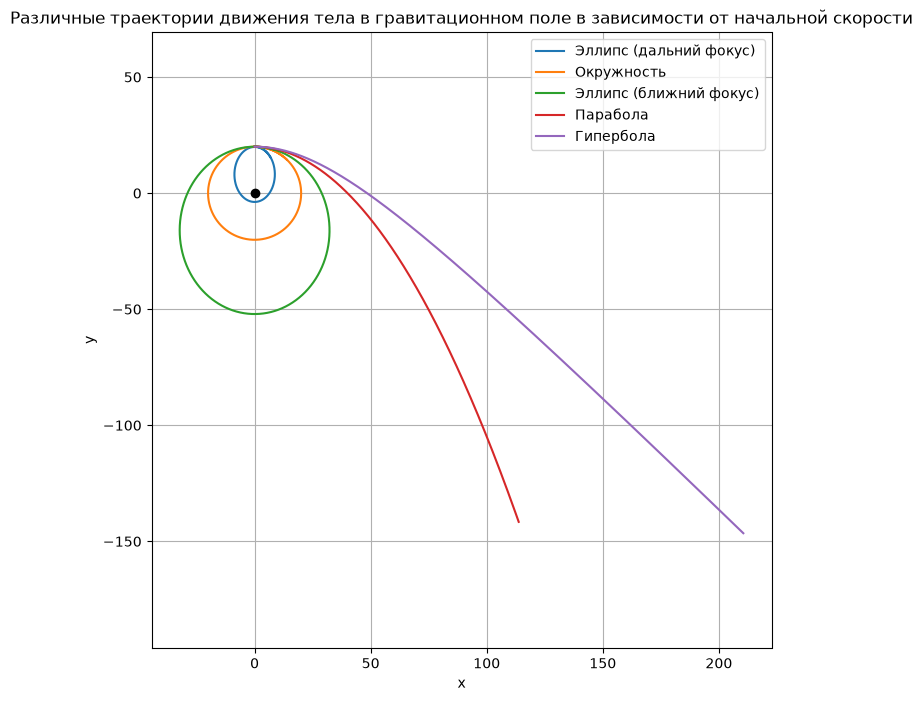

In [115]:
def grav_pot_classic(x, y, m=1, M=1000):
    return - m*M/((x**2 + y**2)**0.5)



Vx0 = [4,7.08,8.5, 10, 11 ]
Steps = [10000,20000,44000, 42000, 42000 ]
labels = ['Эллипс (дальний фокус)', "Окружность", "Эллипс (ближний фокус)", "Парабола", "Гипербола"]


plt.figure(figsize=(8, 8))
for i, label in enumerate(labels):
    x, y = leapfrog(m=1, x0=0, y0=20, vx0=Vx0[i], vy0=0, pot=grav_pot_classic, dt=0.001, steps=Steps[i])
    plt.plot(x, y, label=f'{label}')
plt.plot(0, 0, 'ko')   
plt.axis('equal')
plt.title('Различные траектории движения тела в гравитационном поле в зависимости от начальной скорости')
plt.grid(True)
plt.xlabel('x'); plt.ylabel('y')
plt.legend()
plt.show()


## 3. Движение тела в релятивистском потенциале
В релятивистском потенциале наблюдается смещение точки перицентра орбиты во времени в отличие от классического случая

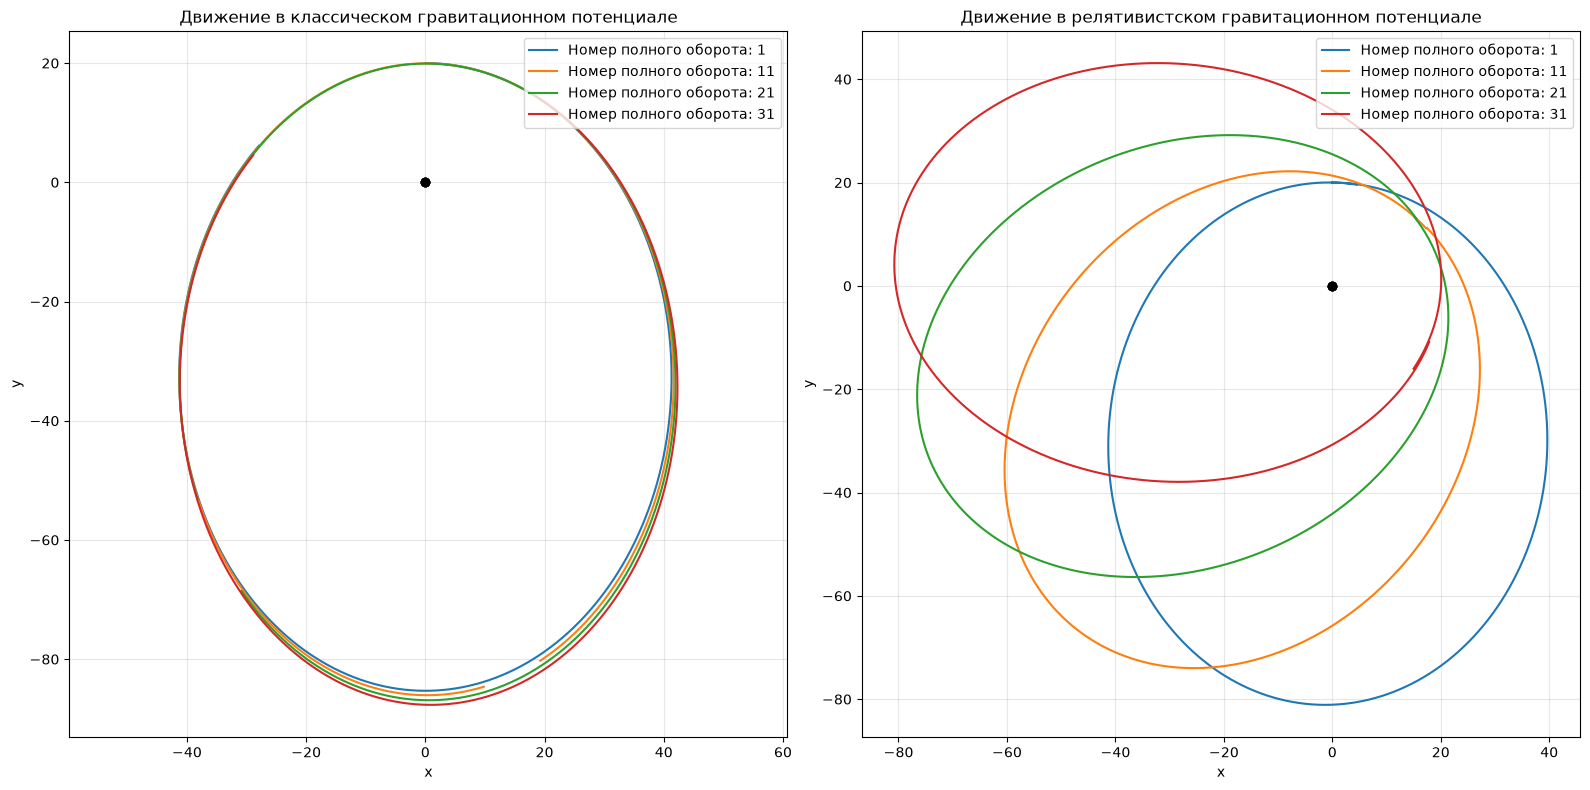

In [116]:
def grav_pot_classic(x, y, m=1, M=1000):
    return - m*M/((x**2 + y**2)**0.5)

def grav_pot_relativistic(x, y, m=1, M=1000):
    return - m * M /((x**2 + y**2)**0.5) - m * M * 3 / ( ( x**2 + y**2 )**1.5 )

xc, yc = leapfrog(m=1, x0=0, y0=20, vx0=9, vy0=0, pot=grav_pot_classic, dt=0.001, steps=3700000)
xr, yr = leapfrog(m=1, x0=0, y0=20, vx0=9, vy0=0, pot=grav_pot_relativistic, dt=0.001, steps=3700000)
n = 0
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
for i in range(4):
        ax1.plot(xc[n:n+72000], yc[n:n+72000], label=f'Номер полного оборота: {i*10 + 1}')
        ax1.set_title('Движение в классическом гравитационном потенциале')
        ax1.set_xlabel('x'); ax1.set_ylabel('y')
        ax1.axis('equal')
        ax1.grid(True, alpha=0.3)
        ax1.legend(loc='upper right')
        ax1.plot(0, 0, 'ko')

        ax2.plot(xr[n:n+72000], yr[n:n+72000], label=f'Номер полного оборота: {i*10 + 1}')
        ax2.set_title('Движение в релятивистском гравитационном потенциале')
        ax2.set_xlabel('x'); ax2.set_ylabel('y')
        ax2.grid(True, alpha=0.3)
        ax2.legend(loc='upper right')
        ax2.plot(0, 0, 'ko')

        n += 72000*10

plt.tight_layout()
plt.show()
    